# Unit 8 seminar, Task 3: building a recommender system

Notebook: *Machine Learning: Make Your Own Recommender System* (Theobald), supplied by the module, on the
MovieLens 100K dataset (Harper and Konstan, 2015; 943 users, 1,682 films, 100,000 ratings). The module's cells run unchanged.
Everything under **My changes** is mine, and answers the seminar's follow-up questions on SHAP.

Tasks 1 and 2 of the seminar (the Yu, 2024 paper and explainability) are written answers, covered in my
reflection rather than here.

*The comments at the end of the module's own code lines are mine, added to explain what each line does. The module's original comments are unchanged.*

> **Not run (mine):** the install cell below is left as plain text. The packages were already installed.

In [1]:
# Load, examine and prepare dataset

import pandas as pd                                 # tables
import numpy as np                                  # arrays and maths
import zipfile                                      # opening the downloaded zip
import io                                           # treat the downloaded bytes as a file
import requests                                     # downloading
from pathlib import Path                            # file paths


# Download MovieLens 100K
URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"  # where MovieLens 100K lives
DATA_DIR = Path("ml-100k")                          # folder it unzips to

if not DATA_DIR.exists():                           # only download if it isn't here already
    print("Downloading MovieLens 100K...")          # progress message
    r = requests.get(URL)                           # download the zip
    r.raise_for_status()                            # stop with an error if the download failed

    with zipfile.ZipFile(io.BytesIO(r.content)) as z:  # open the zip straight from memory
        z.extractall()                              # unzip into the current folder

print("Dataset ready.")                             # progress message

# If your network blocks downloads, requests.get() will fail.
# Check your connection and/or any other access issues.


# Load ratings
ratings = pd.read_csv(                              # ratings file: one row per rating
    DATA_DIR / "u.data",                            # the file
    sep="\t",                                       # tab separated
    names=["user_id", "item_id", "rating", "timestamp"],  # the file has no header, so name the columns
)


# Load items
items = pd.read_csv(                                # films file: one row per film
    DATA_DIR / "u.item",                            # the file
    sep="|",                                        # separated by |
    encoding="latin-1",                             # older text encoding; some titles have accents
    header=None                                     # no header row
)

item_cols = (                                       # column names for the films file
    ["item_id", "title", "release_date", "video_release_date", "imdb_url"]  # the first five columns
    + [f"genre_{i}" for i in range(19)]             # then 19 yes/no genre columns
)
items.columns = item_cols                           # apply the names


# Validation & diagnostics
print(ratings.head())                               # first few ratings
print(items[["item_id", "title"]].head())           # first few films

assert ratings["rating"].between(1, 5).all()        # every rating is 1 to 5 stars
assert ratings["user_id"].nunique() <= 1000         # about the expected number of users
assert ratings["item_id"].nunique() <= 1700         # about the expected number of films

print("Ratings:", len(ratings))                     # 100,000
print("Users:", ratings["user_id"].nunique())       # 943
print("Items:", ratings["item_id"].nunique())       # 1,682
print("Min/Max timestamp:", ratings["timestamp"].min(), ratings["timestamp"].max())  # time span of the ratings

#Validation is essential. Recommenders are extremely sensitive to wrong/missing columns etc.
# REMEMBER: if your data is wrong, the model might still run, but your results will be meaningless

# Sparsity
# Sparsity measures how empty the user–movie matrix is, which can lead to less reliable recommendations.
# Most recommender datasets tend to be sparse, but this an important metrics to check.

n_users = ratings["user_id"].nunique()              # number of users
n_items = ratings["item_id"].nunique()              # number of films
sparsity = 1 - (len(ratings) / (n_users * n_items))  # share of user x film pairs with no rating
print(f"Sparsity: {sparsity:.4f}")                  # show it

print("Rating distribution:")                       # heading
print(ratings["rating"].value_counts().sort_index())  # how many 1s, 2s, ... 5s


Dataset ready.
   user_id  item_id  rating  timestamp
0      196      242       3  881250949
1      186      302       3  891717742
2       22      377       1  878887116
3      244       51       2  880606923
4      166      346       1  886397596
   item_id              title
0        1   Toy Story (1995)
1        2   GoldenEye (1995)
2        3  Four Rooms (1995)
3        4  Get Shorty (1995)
4        5     Copycat (1995)
Ratings: 100000
Users: 943
Items: 1682
Min/Max timestamp: 874724710 893286638
Sparsity: 0.9370
Rating distribution:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


In [2]:
# Time-aware train/val/test split (80/10/10)
ratings_sorted = ratings.sort_values("timestamp").reset_index(drop=True)  # oldest rating first
n = len(ratings_sorted)                             # number of ratings

train = ratings_sorted.iloc[: int(0.8*n)]           # oldest 80% to train on
val   = ratings_sorted.iloc[int(0.8*n): int(0.9*n)]  # next 10% to check training
test  = ratings_sorted.iloc[int(0.9*n):]            # newest 10% for the final test

assert train["timestamp"].max() <= val["timestamp"].min()  # no training rating is newer than validation
assert val["timestamp"].max() <= test["timestamp"].min()  # no validation rating is newer than test

print("\nSplit sizes:", len(train), len(val), len(test))  # 80,000 / 10,000 / 10,000

#Why time aware? In real life, you recommend based on the past, not the future.
# A random split can accidentally let the model “learn” patterns that rely on future interactions (data leakage).


Split sizes: 80000 10000 10000


In [3]:
# Build a Baseline Model.
# They are a benchmark against which more complex models can be evaluated.

from sklearn.metrics import mean_squared_error, mean_absolute_error  # error measures
import numpy as np # Import numpy if not already imported, for np.sqrt

#Baselines (sanity checks)
def eval_constant(df, c):                           # score a model that always predicts the same number c
    y_true = df["rating"].values.astype(float)      # the real ratings
    y_pred = np.full_like(y_true, c, dtype=float)   # c for every row
    # Calculate MSE first, then take the square root for RMSE
    mse = mean_squared_error(y_true, y_pred)        # mean squared error
    rmse = np.sqrt(mse)                             # RMSE: typical miss, in stars
    mae = mean_absolute_error(y_true, y_pred)       # average miss, in stars
    return rmse, mae                                # both scores

global_mean = train["rating"].mean()                # average rating across all training data
print("\nBaseline(global mean) VAL:", eval_constant(val, global_mean))  # always predict the average: validation
print("Baseline(global mean) TEST:", eval_constant(test, global_mean))  # same on test

# Bias baseline: r_hat = mu + b_u + b_i (with regularization)
mu = train["rating"].mean()                         # overall average rating
lambda_reg = 10.0                                   # shrinks biases of users and films with few ratings towards zero

user_sum = train.groupby("user_id")["rating"].sum()  # total stars given by each user
user_cnt = train.groupby("user_id")["rating"].count()  # number of ratings by each user
item_sum = train.groupby("item_id")["rating"].sum()  # total stars received by each film
item_cnt = train.groupby("item_id")["rating"].count()  # number of ratings for each film

b_u = ((user_sum - user_cnt * mu) / (user_cnt + lambda_reg)).to_dict()  # user bias: how far above or below average they rate
b_i = ((item_sum - item_cnt * mu) / (item_cnt + lambda_reg)).to_dict()  # film bias: how far above or below average it is rated

def predict_bias(df):                               # prediction = average + user bias + film bias
    bu = df["user_id"].map(b_u).fillna(0.0).values  # each row's user bias; 0 for a user never seen
    bi = df["item_id"].map(b_i).fillna(0.0).values  # each row's film bias; 0 for a film never seen
    return mu + bu + bi                             # the prediction

def eval_model(df, pred_fn):                        # score any prediction function
    y_true = df["rating"].values.astype(float)      # the real ratings
    y_pred = pred_fn(df).astype(float)              # its predictions
    # Calculate MSE first, then take the square root for RMSE
    mse = mean_squared_error(y_true, y_pred)        # mean squared error
    rmse = np.sqrt(mse)                             # RMSE: typical miss, in stars
    mae = mean_absolute_error(y_true, y_pred)       # average miss, in stars
    return rmse, mae                                # both scores

print("\nBias baseline VAL:", eval_model(val, predict_bias))  # bias model: validation
print("\nBias baseline TEST:", eval_model(test, predict_bias))  # bias model: test

# Bias account for people's different approach.
# Expected outcome: bias baseline should beat global mean baseline.


Baseline(global mean) VAL: (np.float64(1.0979175162552057), 0.92612078)
Baseline(global mean) TEST: (np.float64(1.1399315560593977), 0.96937963)

Bias baseline VAL: (np.float64(1.0191052016857542), 0.810877103220018)

Bias baseline TEST: (np.float64(1.0446204580678322), 0.8480805896543465)


In [4]:
# Matrix Factorization assumes each user and each movie can be described by hidden features
#We don’t label these features. The model discovers them automatically.

import numpy as np                                  # arrays and maths
from tqdm import trange                             # range with a progress bar

# Define the mapping function to convert user/item IDs to contiguous indices
user_ids = sorted(ratings["user_id"].unique())      # every user id
item_ids = sorted(ratings["item_id"].unique())      # every film id

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}  # user id -> row number 0, 1, 2 ...
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}  # film id -> row number

def to_idx(df):                                     # turn a ratings table into three arrays
    u_idx = df["user_id"].map(user_to_idx).values   # user row numbers
    m_idx = df["item_id"].map(item_to_idx).values   # film row numbers
    r = df["rating"].values                         # the ratings
    return u_idx, m_idx, r                          # all three

#Matrix Factorization (SGD==stochastic gradient descent)

train_u, train_m, train_r = to_idx(train)           # training data as arrays
val_u,   val_m,   val_r   = to_idx(val)             # validation data as arrays
test_u,  test_m,  test_r  = to_idx(test)            # test data as arrays

n_users = len(user_ids)                             # number of users
n_items = len(item_ids)                             # number of films

rng = np.random.default_rng(42)                     # seeded random numbers
k = 32                                              # 32 hidden features per user and per film
lr = 0.01                                           # learning rate
reg = 0.02                                          # regularisation: keeps the numbers small to limit overfitting
epochs = 30                                         # passes over the training data

mu_mf = train_r.mean()                              # overall average rating
bu = np.zeros(n_users)                              # user biases, start at 0
bi = np.zeros(n_items)                              # film biases, start at 0
P = 0.1 * rng.standard_normal((n_users, k))         # user feature vectors, small random start
Q = 0.1 * rng.standard_normal((n_items, k))         # film feature vectors, small random start

def mf_predict(u_idx, m_idx):                       # predicted rating for user/film pairs
    return mu_mf + bu[u_idx] + bi[m_idx] + np.sum(P[u_idx] * Q[m_idx], axis=1)  # average + biases + how well user and film features match

def rmse_vec(y_true, y_pred):                       # RMSE for arrays
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))  # square root of the mean squared error

history = []                                        # train and validation RMSE after each epoch
print("\nTraining MF...")                           # progress message
for epoch in trange(1, epochs + 1):                 # each epoch
    perm = rng.permutation(len(train_r))            # shuffle the order of the ratings
    u_sh, m_sh, r_sh = train_u[perm], train_m[perm], train_r[perm]  # apply the shuffle

    for u, m, r in zip(u_sh, m_sh, r_sh):           # one rating at a time (stochastic gradient descent)
        pred = mu_mf + bu[u] + bi[m] + P[u].dot(Q[m])  # current prediction
        err = r - pred                              # how far off it is

        bu[u] += lr * (err - reg * bu[u])           # nudge the user bias
        bi[m] += lr * (err - reg * bi[m])           # nudge the film bias

        pu = P[u].copy()                            # keep the old user vector
        qi = Q[m].copy()                            # and the old film vector, so both updates use the old values
        P[u] += lr * (err * qi - reg * pu)          # nudge the user's features
        Q[m] += lr * (err * pu - reg * qi)          # nudge the film's features

    train_rmse = rmse_vec(train_r, mf_predict(train_u, train_m))  # error on training data
    val_rmse   = rmse_vec(val_r,   mf_predict(val_u,   val_m))  # error on validation data
    history.append((epoch, train_rmse, val_rmse))   # save both

    if epoch == 1 or epoch % 5 == 0:                # report every 5 epochs
        print(f"Epoch {epoch:02d} | train RMSE={train_rmse:.4f} | val RMSE={val_rmse:.4f}")  # progress

test_pred = mf_predict(test_u, test_m)              # predictions for the test ratings
test_rmse = rmse_vec(test_r, test_pred)             # test RMSE
test_mae  = float(np.mean(np.abs(test_r - test_pred)))  # test MAE
print("\nMF TEST RMSE:", test_rmse, " MAE:", test_mae)  # final scores


Training MF...


  3%|▎         | 1/30 [00:00<00:17,  1.64it/s]

Epoch 01 | train RMSE=0.9554 | val RMSE=1.0388


 17%|█▋        | 5/30 [00:03<00:15,  1.62it/s]

Epoch 05 | train RMSE=0.8905 | val RMSE=1.0301


...

Epoch 20 | train RMSE=0.6338 | val RMSE=1.0381


 83%|████████▎ | 25/30 [00:15<00:03,  1.64it/s]

Epoch 25 | train RMSE=0.5813 | val RMSE=1.0404


100%|██████████| 30/30 [00:18<00:00,  1.63it/s]

Epoch 30 | train RMSE=0.5458 | val RMSE=1.0429

MF TEST RMSE: 1.0399901844123336  MAE: 0.8358307064794835


It is important here to look at your results.
Training diagnostics: train RMSE vs val RMSE
If both go down → good.
BUT
If train goes down but val goes up → overfitting.
Is it the case here? Check.
If you detect overfitting, one simple fix is to stop early (fewer epochs) in your training routine.

In [5]:
# Top-N recommendations + ranking validation
#Why do we use a ranking metric? Because of what the RS do.
# They are judged on their usefulness: “Did we put the right movies near the top?”


train_items_by_user = train.groupby("user_id")["item_id"].apply(set).to_dict()  # films each user already rated
test_pos = test[test["rating"] >= 4].groupby("user_id")["item_id"].apply(set).to_dict()  # films each user liked (4+ stars) in the test period

all_item_idx = np.arange(n_items)                   # every film's row number

u2i = user_to_idx # Alias user_to_idx to u2i
m2i = item_to_idx # Alias item_to_idx to m2i

def ndcg_at_k(relevances, k):                       # NDCG: rewards putting hits near the top of the list
    rel = relevances[:k]                            # the top k
    dcg = sum((2**r - 1) / np.log2(i + 2) for i, r in enumerate(rel))  # score of this order; lower places count less
    ideal = sorted(relevances, reverse=True)[:k]    # the best possible order
    idcg = sum((2**r - 1) / np.log2(i + 2) for i, r in enumerate(ideal))  # score of the best order
    return 0.0 if idcg == 0 else float(dcg / idcg)  # 1 = perfect order

def recommend_for_user(user_id, K=10):              # top K unseen films for one user
    uidx = u2i[user_id]                             # the user's row number
    seen = train_items_by_user.get(user_id, set())  # films they already rated
    seen_idx = np.array([m2i[m] for m in seen if m in m2i], dtype=int)  # as row numbers

    u_vec = np.full(n_items, uidx, dtype=int)       # the user's row number repeated once per film
    scores = mf_predict(u_vec, all_item_idx)        # predicted rating for every film

    scores[seen_idx] = -1e9  # filter seen items

    topk_idx = np.argpartition(-scores, K)[:K]      # the K highest scores, in any order (fast)
    topk_idx = topk_idx[np.argsort(-scores[topk_idx])]  # now sort those K, best first

    topk_item_ids = [item_ids[i] for i in topk_idx]  # row numbers back to film ids
    return topk_item_ids, scores[topk_idx]          # films and their scores

def ranking_eval(K=10, max_users=500):              # how good are the top-K lists?
    users = list(test["user_id"].unique())[:max_users]  # up to 500 test users
    precs, recs, ndcgs, cover_items = [], [], [], set()  # results collected per user

    for u in users:                                 # each user
        gt = test_pos.get(u, set())                 # films they actually liked later
        if not gt:                                  # skip users with no liked films
            continue                                # next user

        recs_u, _ = recommend_for_user(u, K=K)      # their top-K list
        cover_items.update(recs_u)                  # remember every film recommended

        hits = [1 if m in gt else 0 for m in recs_u]  # 1 where a recommendation was a film they liked
        precs.append(np.mean(hits))                 # precision: share of the list that were hits
        recs.append(np.sum(hits) / len(gt))         # recall: share of liked films that were found
        ndcgs.append(ndcg_at_k(hits, K))            # NDCG for this user

    coverage = len(cover_items) / n_items           # share of all films that ever got recommended
    return {                                        # averages across users
        "precision@k": float(np.mean(precs)) if precs else 0.0,  # average precision
        "recall@k": float(np.mean(recs)) if recs else 0.0,  # average recall
        "ndcg@k": float(np.mean(ndcgs)) if ndcgs else 0.0,  # average NDCG
        "item_coverage": float(coverage),           # catalogue coverage
        "users_evaluated": int(len(precs))          # how many users were scored
    }

print("\nRanking metrics:", ranking_eval(K=10))     # show them


Ranking metrics: {'precision@k': 0.14183006535947715, 'recall@k': 0.051162096261366884, 'ndcg@k': 0.30398477864123846, 'item_coverage': 0.14625445897740785, 'users_evaluated': 153}


Metrics explained:

Precision@K: among the top K recommendations, what fraction are relevant?

Recall@K: among the relevant items the user had, what fraction did we retrieve in top K?

NDCG@K: like precision but rewards correct items appearing earlier in the list (higher rank is better).

Item coverage: how many distinct items appear in recommendations across users.

Low coverage means the model recommends the same popular movies to everyone.

In [6]:
# Diagnostics: cold-start slices + popularity bias proxy
# It is important to classify the users in RS
# Users with few ratings are hard (COLD USERS): not enough data to learn a stable preference vector
# This is why we compute RMSE separately.

user_counts = train.groupby("user_id")["rating"].count()  # training ratings per user

def slice_users(min_ratings, max_ratings=None):     # users with a given number of ratings
    if max_ratings is None:                         # no upper limit
        return set(user_counts[user_counts >= min_ratings].index)  # at least min_ratings
    return set(user_counts[(user_counts >= min_ratings) & (user_counts <= max_ratings)].index)  # between the two limits

cold_users = slice_users(1, 10)                     # users with 1 to 10 ratings
warm_users = slice_users(50, None)                  # users with 50 or more

def rmse_on_user_subset(df, user_set):              # RMSE for one group of users only
    df2 = df[df["user_id"].isin(user_set)]          # their rows
    if len(df2) == 0:                               # no rows for this group
        return None                                 # nothing to score
    u, m, r = to_idx(df2)                           # as arrays
    pred = mf_predict(u, m)                         # predictions
    return rmse_vec(r, pred)                        # their RMSE

print("\nRMSE test cold users (1-10 ratings):", rmse_on_user_subset(test, cold_users))  # error for cold users
print("RMSE test warm users (>=50 ratings):", rmse_on_user_subset(test, warm_users))  # error for warm users

item_pop = train.groupby("item_id")["rating"].count().to_dict()  # number of ratings per film

def avg_popularity_of_recs(sample_users=200, K=10):  # how popular are the films it recommends?
    users = list(test["user_id"].unique())[:sample_users]  # first 200 test users
    pops = []                                       # popularity of each recommended film
    for u in users:                                 # each user
        recs_u, _ = recommend_for_user(u, K=K)      # their top-K list
        pops.extend([item_pop.get(m, 0) for m in recs_u])  # add their popularity
    return float(np.mean(pops)), float(np.median(pops))  # average and median

print("Avg/Median popularity of recs:", avg_popularity_of_recs())  # show them


RMSE test cold users (1-10 ratings): 1.2365472979247374
RMSE test warm users (>=50 ratings): 1.0095493780701932
Avg/Median popularity of recs: (159.83072289156627, 148.0)


In [7]:
from sklearn.linear_model import Ridge              # linear model used as a stand-in for the recommender
import shap                                         # SHAP: splits a prediction into each feature's share

# Explainable AI (SHAP) for MF prediction
def mf_feature_matrix(u_idx, m_idx):                # describe each prediction as 34 numbers
    inter = P[u_idx] * Q[m_idx]  # (n, k)
    return np.column_stack([bu[u_idx], bi[m_idx], inter])  # user bias, film bias, 32 feature products

# Surrogate training sample (approximate MF behavior)
N_SAMPLE = 20000                                    # how many training ratings to fit the stand-in on
idx = rng.choice(len(train_r), size=min(N_SAMPLE, len(train_r)), replace=False)  # random sample of rows

X_surr = mf_feature_matrix(train_u[idx], train_m[idx])  # features for those rows
y_surr = mf_predict(train_u[idx], train_m[idx])     # the recommender's predictions, as the target

surr = Ridge(alpha=1.0)                             # the stand-in (surrogate) model
surr.fit(X_surr, y_surr)                            # learn to copy the recommender

pred_check = surr.predict(X_surr)                   # the stand-in's predictions
print("\nSurrogate fidelity RMSE (surrogate vs MF):", rmse_vec(y_surr, pred_check))  # how closely it copies; near 0 = faithful

# SHAP for linear surrogate
explainer = shap.LinearExplainer(surr, X_surr, feature_perturbation="interventional")  # SHAP for a linear model
feature_names = ["user_bias", "item_bias"] + [f"latent_inter_{j}" for j in range(k)]  # names for the 34 features

def explain_prediction(user_id, item_id, top_n=10):  # explain one user/film prediction
    uidx = u2i[user_id]                             # the user's row number
    midx = m2i[item_id]                             # the film's row number

    x = mf_feature_matrix(np.array([uidx]), np.array([midx]))  # its 34 features
    pred_mf = float(mf_predict(np.array([uidx]), np.array([midx]))[0])  # the recommender's prediction
    pred_surr = float(surr.predict(x)[0])           # the stand-in's prediction

    shap_vals = explainer.shap_values(x)[0]         # each feature's push up or down
    base = float(explainer.expected_value)          # starting point: the average prediction

    title = items.loc[items["item_id"] == item_id, "title"].values  # look up the film title
    title = title[0] if len(title) else str(item_id)  # fall back to the id if not found

    contribs = list(zip(feature_names, shap_vals))  # pair each name with its value
    contribs.sort(key=lambda t: abs(t[1]), reverse=True)  # biggest effect first

    print(f"\nExplanation for: User {user_id} -> Movie {item_id} ({title})")  # heading
    print(f"MF prediction:        {pred_mf:.3f}")   # recommender
    print(f"Surrogate prediction: {pred_surr:.3f}")  # stand-in
    print(f"SHAP base value:      {base:.3f}")      # starting point
    print("Top SHAP contributions:")                # heading
    for name, val in contribs[:top_n]:              # the biggest few
        print(f"  {name:>16}: {val:+.4f}")          # + pushes the rating up, - pushes it down

    return shap_vals, x                             # for further use

# Example explanation on a real test row
row = test.iloc[0]                                  # first test rating
_ = explain_prediction(int(row.user_id), int(row.item_id), top_n=10)  # explain it

/home/z331992/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Surrogate fidelity RMSE (surrogate vs MF): 0.002701144912761898

Explanation for: User 90 -> Movie 900 (Kundun (1997))
MF prediction:        3.928
Surrogate prediction: 3.929
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: +0.2410
         user_bias: +0.1587
   latent_inter_13: -0.0328
   latent_inter_24: +0.0310
    latent_inter_3: +0.0225
   latent_inter_17: -0.0217
   latent_inter_16: +0.0210
   latent_inter_11: +0.0180
   latent_inter_28: -0.0178
    latent_inter_0: -0.0175


/home/z331992/.local/lib/python3.10/site-packages/shap/explainers/_linear.py:99: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Matrix Factorization predicts a rating using internal parameters (biases and latent vectors), not using explicit  “features” like genre or age.
SHAP, however, explains predictions by attributing them to input features. Because MF does not naturally expose such features, we re-express each MF prediction as a feature vector built from its own components, then train a simple model to reproduce MF’s output. SHAP is applied to this simple model, allowing us to explain which parts of the MF prediction mattered most. The surrogate is a simple, interpretable model that imitates the behaviour of a more complex model so that we can explain its predictions.
The whole idea is that we can EXPLAIN the results we got with MF using a more transparent approach (==explanaible AI)


## My changes

### 1. Is it overfitting?

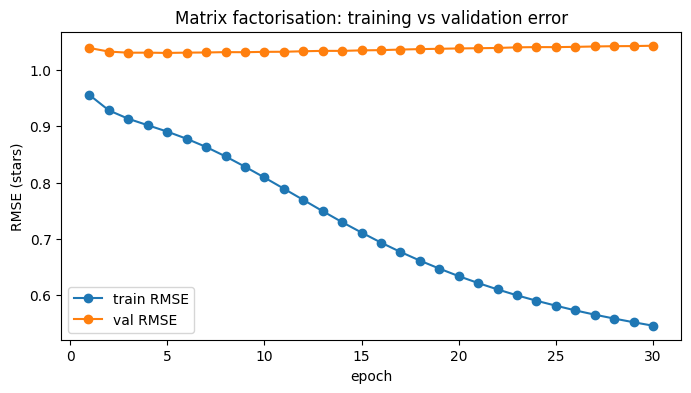

Validation error is lowest at epoch 5 (1.0301); after 30 epochs it is 1.0429.
Training error fell from 0.9554 to 0.5458.


In [8]:
import matplotlib.pyplot as plt                      # plotting
h = pd.DataFrame(history, columns=["epoch", "train RMSE", "val RMSE"]).set_index("epoch")   # the module's training log as a table
h.plot(figsize=(8, 4), marker="o", title="Matrix factorisation: training vs validation error")   # both curves on one plot
plt.ylabel("RMSE (stars)"); plt.show()  # label and draw
best = h["val RMSE"].idxmin()                        # the epoch where validation error was lowest
print(f"Validation error is lowest at epoch {best} ({h.loc[best, 'val RMSE']:.4f}); "  # best epoch vs where training stopped
      f"after 30 epochs it is {h['val RMSE'].iloc[-1]:.4f}.")
print(f"Training error fell from {h['train RMSE'].iloc[0]:.4f} to {h['train RMSE'].iloc[-1]:.4f}.")  # how far training error dropped

### 2. SHAP follow-up questions: a good film, a film predicted low, and does it make sense?

In [9]:
# First: who is the module's example user?
cold = int(test.iloc[0].user_id)                     # the user in the module's own SHAP example (first test row)
print(f"The module's example explains user {cold}, who has {int((train.user_id == cold).sum())} ratings in the training data.")  # how much the model knows about this user
# The module draws P first from default_rng(42), so its starting values can be recreated exactly.
P_init = 0.1 * np.random.default_rng(42).standard_normal((n_users, k))   # the user vectors before any training
print(f"Is their latent vector still exactly its random starting value? {np.allclose(P[u2i[cold]], P_init[u2i[cold]])}")  # True = never updated by training
# Control check: a user who does have training ratings should have moved away from their starting value
print(f"Same check for a user with ratings (user {int(train.user_id.iloc[0])}): "  # control: should be False
      f"{np.allclose(P[u2i[int(train.user_id.iloc[0])]], P_init[u2i[int(train.user_id.iloc[0])]])}")

The module's example explains user 90, who has 0 ratings in the training data.
Is their latent vector still exactly its random starting value? True
Same check for a user with ratings (user 259): False


So the module's example is a **cold-start user**: the time-based split put all of their ratings in the later
period. The model has learned nothing about them. I answer the follow-up questions with a user the model has
actually learned from, then come back to the cold user.

In [10]:
in_test = test.user_id.unique()                      # users who appear in the test period
counts = train[train.user_id.isin(in_test)].groupby("user_id").size()   # how many training ratings each of them has
user = int(counts.idxmax())                          # the one the model knows best
seen = set(train[train.user_id == user].item_id)     # films this user rated in training
print(f"User {user} rated {len(seen)} films in the training data. Their five highest-rated:")  # how much the model knows about this user
top5 = train[train.user_id == user].sort_values(["rating", "timestamp"], ascending=False).head(5)   # their favourites
print(top5.merge(items[["item_id", "title"]], on="item_id")[["title", "rating"]].to_string(index=False))   # with titles

def find(title_start):                               # look up a film's id from the start of its title
    return int(items.loc[items.title.str.startswith(title_start), "item_id"].iloc[0])  # first film whose title starts that way

good = find("Star Wars (1977)")                      # "a movie you know is good"
scores = mf_predict(np.full(n_items, u2i[user]), all_item_idx)   # the model's predicted rating for every film, for this user
unseen = [i for i in range(n_items) if item_ids[i] not in seen]  # films this user hasn't rated
low = item_ids[min(unseen, key=lambda i: scores[i])] # "a movie predicted low": their lowest-predicted unseen film
print(f"\nA film I know is good: Star Wars (1977), item {good}. Already rated by this user? {good in seen}")  # and whether it was in their training data

User 13 rated 608 films in the training data. Their five highest-rated:
                        title  rating
                Kundun (1997)       5
    As Good As It Gets (1997)       5
        Night on Earth (1991)       5
Great Day in Harlem, A (1994)       5
           Stand by Me (1986)       5

A film I know is good: Star Wars (1977), item 50. Already rated by this user? True


In [11]:
actual = train[(train.user_id == user) & (train.item_id == good)].rating   # what they really gave Star Wars
print(f"User {user} actually gave Star Wars {int(actual.iloc[0])} stars (this rating was in the training data).")  # the real rating, to compare with the prediction
shap_good, _ = explain_prediction(user, good, top_n=6)   # the module's SHAP explanation for this prediction

User 13 actually gave Star Wars 5 stars (this rating was in the training data).

Explanation for: User 13 -> Movie 50 (Star Wars (1977))
MF prediction:        5.256
Surrogate prediction: 5.250
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: +0.7453
    latent_inter_0: -0.5146
    latent_inter_6: +0.3934
   latent_inter_24: +0.3512
    latent_inter_7: +0.2589
   latent_inter_10: -0.2366


In [12]:
shap_low, _ = explain_prediction(user, low, top_n=6)  # SHAP explanation for the lowest-predicted film


Explanation for: User 13 -> Movie 368 (Bio-Dome (1996))
MF prediction:        0.301
Surrogate prediction: 0.307
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: -1.6809
   latent_inter_12: -0.3271
   latent_inter_21: -0.2646
   latent_inter_13: -0.2219
   latent_inter_30: -0.2014
   latent_inter_31: -0.2002


In [13]:
# Sense-check the biggest SHAP driver: does the learned item bias match what people actually think of a film?
stats_ = train.groupby("item_id")["rating"].agg(["mean", "count"])   # real average rating and number of ratings per film
for name, item in [("Star Wars", good), ("lowest-predicted film", low)]:   # the two films explained above
    s_ = stats_.loc[item]                            # that film's real stats
    print(f"{name:<22} learned item bias {bi[m2i[item]]:+.3f}   average rating {s_['mean']:.2f} from {int(s_['count'])} people")  # learned bias next to the real average
both = stats_.join(pd.Series(bi, index=item_ids).rename("item_bias"))   # put learned bias next to the real average
print(f"\nAcross all films, item bias vs average rating: correlation {both['item_bias'].corr(both['mean']):.2f}")  # does the bias track real opinion overall?

Star Wars              learned item bias +0.889   average rating 4.36 from 473 people
lowest-predicted film  learned item bias -1.537   average rating 1.89 from 28 people

Across all films, item bias vs average rating: correlation 0.74


In [14]:
# How much of each explanation is something a person could understand (the two biases)
# vs the 32 unnamed latent features?
shap_cold, _ = explain_prediction(cold, good, top_n=3)   # the cold user, for comparison
for name, sv in [(f"user {user}, Star Wars", shap_good), (f"user {user}, lowest film", shap_low),  # the three explanations to compare
                 (f"cold user {cold}, Star Wars", shap_cold)]:  # the cold user, for comparison
    total = np.abs(sv).sum()                         # total size of all SHAP contributions
    # first two SHAP values are user_bias and item_bias; the remaining 32 are the latent features
    print(f"{name:<28} biases explain {np.abs(sv[:2]).sum() / total:.0%}, the 32 latent features {np.abs(sv[2:]).sum() / total:.0%}")  # share of the explanation a person could read


Explanation for: User 90 -> Movie 50 (Star Wars (1977))
MF prediction:        4.455
Surrogate prediction: 4.455
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: +0.7453
         user_bias: +0.1587
   latent_inter_27: -0.1417
user 13, Star Wars           biases explain 20%, the 32 latent features 80%
user 13, lowest film         biases explain 39%, the 32 latent features 61%
cold user 90, Star Wars      biases explain 54%, the 32 latent features 46%


### 3. Predictions off the star scale

In [15]:
all_scores = P @ Q.T + bu[:, None] + bi[None, :] + mu_mf     # every user x every film, same formula as mf_predict
print(f"Predicted ratings range from {all_scores.min():.2f} to {all_scores.max():.2f} stars on a 1-5 scale.")  # lowest and highest prediction
print(f"{((all_scores < 1) | (all_scores > 5)).mean():.1%} of all user-film predictions fall outside 1-5.")  # share of predictions off the 1-5 scale
clipped = np.clip(test_pred, 1, 5)                   # force test predictions into the valid range
print(f"Test RMSE as trained: {rmse_vec(test_r, test_pred):.4f}   clipped to 1-5: {rmse_vec(test_r, clipped):.4f}")  # does clipping change the error?

Predicted ratings range from -1.76 to 6.90 stars on a 1-5 scale.
0.7% of all user-film predictions fall outside 1-5.
Test RMSE as trained: 1.0400   clipped to 1-5: 1.0399


### 4. Popularity bias: what does it actually recommend?

In [16]:
popularity = train.groupby("item_id").size()         # number of training ratings per film
recs = []                                            # every film recommended, across users
for u in list(test["user_id"].unique())[:200]:       # the first 200 test users
    ids, _ = recommend_for_user(u, K=10)             # the module's top-10 recommendations for that user
    recs.extend(ids)                                 # add them to the pile
recs = pd.Series(recs)                               # as a pandas series for counting
print(f"Top-10 lists for 200 users contain {recs.nunique()} different films out of {n_items}.")  # how many different films get recommended
print(f"Median number of training ratings for a recommended film: {popularity.reindex(recs).median():.0f}, "  # recommended vs typical popularity
      f"for a typical film: {popularity.median():.0f}")
print("Most recommended:")  # heading
print(items.set_index("item_id").loc[recs.value_counts().head(5).index, "title"].to_string())   # the five most frequent

Top-10 lists for 200 users contain 268 different films out of 1682.
Median number of training ratings for a recommended film: 148, for a typical film: 23
Most recommended:
64                      Shawshank Redemption, The (1994)
483                                    Casablanca (1942)
408                                Close Shave, A (1995)
169                           Wrong Trousers, The (1993)
114    Wallace & Gromit: The Best of Aardman Animatio...


## What I took from it


**Does the model beat the simple baselines?**
- Barely. Matrix factorisation (Koren, Bell and Volinsky, 2009) learns hidden taste features for every
  user and film. On the test set, guessing the overall average rating is 1.140 stars out (RMSE). The bias baseline,
  which just adds "this user rates high or low" and "this film is liked or not", gets 1.045. The full matrix
  factorisation model gets 1.040. Thirty passes of training buy 0.005 of a star over a two-line formula.
- **It overfits, as the module warns.** Training error falls from 0.96 to 0.55, but validation error is lowest
  at epoch 5 and climbs after that. Even at its best epoch (1.030) it doesn't beat the bias baseline on
  validation (1.019). The fix the notebook suggests, stopping early, helps, but the bigger lesson is that the
  simple model was already most of the way there.

**SHAP follow-up questions** (SHAP: Lundberg and Lee, 2017)
- **The module's own example is a cold-start user.** User 90 has no ratings in the training data, because the
  time-based split put all of their ratings in the later period. I checked their latent vector: it is
  exactly its random starting value, untouched by training. So nearly half of their SHAP explanation (46%)
  comes from "latent features" that are pure random noise. The explanation looks precise, with names and
  numbers, but it explains nothing. That's the most important thing I found in this exercise.
- **A film I know is good:** Star Wars, for user 13, who rated 608 films. The model predicts 5.26 stars and
  they actually gave it 5. The biggest single driver is the item bias (+0.75): people in general rate Star
  Wars highly. That makes sense. But 80% of the explanation is spread across 32 features called
  `latent_inter_0`, `latent_inter_6` and so on. Nobody can say what `latent_inter_6` means, so the
  explanation can't be checked by a person.
- **A film predicted low:** Bio-Dome (1996), predicted at 0.30 stars. The item bias dominates (−1.68), and that
  matches reality: its average rating is 1.89 from 28 people. Across all films the learned item bias tracks
  the real average rating closely (correlation 0.74). So the parts of the explanation a person *can*
  understand do make sense.
- **Does the explanation make sense?** Partly. The "surrogate" model copies the real one almost perfectly
  (fidelity error 0.003), but that's because the matrix factorisation prediction is literally a sum of
  those same pieces. SHAP is really just restating the model's own arithmetic. It tells you *which numbers*
  pushed the prediction, not *why* in human terms, like genre, actors or era. For a user wanting to know
  "why was I recommended this?", "latent feature 6" is not an answer.

**Other things I noticed**
- **Predictions go off the scale:** from −1.76 to 6.90 stars on a 1 to 5 scale. Only 0.7% of predictions, and
  clipping them barely changes the error, but showing a user "6.9 stars" would look broken.
- **New users get worse predictions:** RMSE 1.24 for users with 1 to 10 ratings against 1.01 for users with
  50 or more. That's the cold-start problem in numbers.
- **It recommends what's already popular.** A typical film has 23 ratings. The median recommended film has
  148. Across 200 users' top-10 lists, only 268 of 1,682 films ever appear. Shawshank, Casablanca and Wallace
  & Gromit come up again and again. That's good for accuracy but it narrows what people discover, and it
  makes popular films more popular. That is a real ethical and commercial question for platforms like
  Netflix, not just a technical one.